<a href="https://colab.research.google.com/github/Islamintech/AI/blob/main/AI_Assignment1_20252403_%EC%9D%B4%EC%8A%AC%EB%A1%AC%EB%B2%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Assignment #1 — Problem 6
Perceptron with vectorized `evaluate` and `train` (no for-loops).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Load data & preprocess

In [ ]:
data = np.loadtxt('perceptron_toydata.txt')
X, y = data[:, :2], data[:, -1]
X = np.insert(X, obj=0, values=1, axis=1)
y = (y - 0.5) * 2

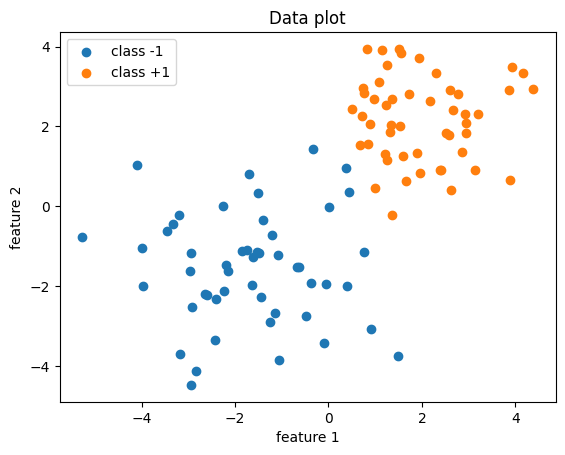

In [ ]:
plt.scatter(X[y==-1,1], X[y==-1,2], label='class -1')
plt.scatter(X[y==1,1], X[y==1,2], label='class +1')
plt.title('Data plot')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.legend()
plt.show()

## (a) Perceptron_vectorized
- `evaluate`: $s = Xw$ for all samples at once, $\hat y = \tau(s)$, and $Y$ = indices where $\hat y \neq y$
- `train`: $w \leftarrow w + \rho \sum_{x_k \in Y} y_k x_k = w + \rho\, (y_Y^T X_Y)$

In [ ]:
class Perceptron_vectorized():
  def __init__(self):
    np.random.seed(4)
    self.w = np.random.randn(3)
    self.lr = 0.002

  def evaluate(self, X, y):
    weighted_sum = X @ self.w
    y_pred = np.where(weighted_sum >= 0, 1, -1)
    self.Y = np.where(y_pred != y)[0]

    print(f'{len(y)-len(self.Y)} samples are correctly classified, {len(self.Y)} samples are incorrectly classified')

  def train(self, X, y):

    self.w += self.lr * (y[self.Y] @ X[self.Y])

## (b) Create perceptron and classify (before training)

In [ ]:
perceptron = Perceptron_vectorized()

perceptron.evaluate(X, y)

24 samples are correctly classified, 76 samples are incorrectly classified


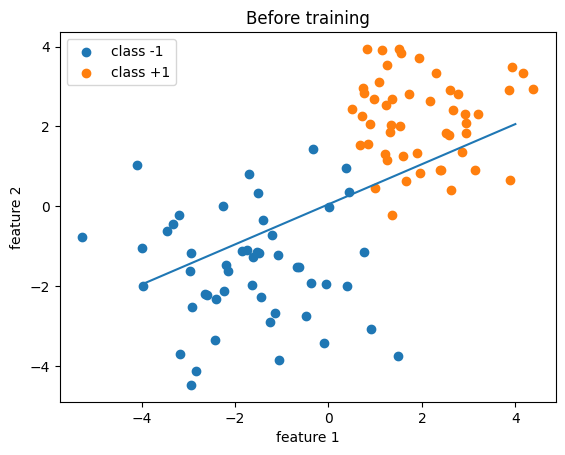

In [ ]:
x1_min = -4
x2_min = -(perceptron.w[0] + perceptron.w[1] * x1_min)/ perceptron.w[2]
x1_max = +4
x2_max = -(perceptron.w[0] + perceptron.w[1] * x1_max)/ perceptron.w[2]

plt.plot([x1_min, x1_max], [x2_min, x2_max])
plt.scatter(X[y==-1,1], X[y==-1,2], label='class -1')
plt.scatter(X[y==1,1], X[y==1,2], label='class +1')
plt.title('Before training')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.legend()
plt.show()

## Train 100 times (gradient descent)

In [ ]:
for i in range(100):
  perceptron.train(X, y)
  perceptron.evaluate(X, y)
print(perceptron.w)

56 samples are correctly classified, 44 samples are incorrectly classified
73 samples are correctly classified, 27 samples are incorrectly classified
84 samples are correctly classified, 16 samples are incorrectly classified
87 samples are correctly classified, 13 samples are incorrectly classified
91 samples are correctly classified, 9 samples are incorrectly classified
91 samples are correctly classified, 9 samples are incorrectly classified
91 samples are correctly classified, 9 samples are incorrectly classified
92 samples are correctly classified, 8 samples are incorrectly classified
94 samples are correctly classified, 6 samples are incorrectly classified
94 samples are correctly classified, 6 samples are incorrectly classified
94 samples are correctly classified, 6 samples are incorrectly classified
94 samples are correctly classified, 6 samples are incorrectly classified
94 samples are correctly classified, 6 samples are incorrectly classified
94 samples are correctly classifie

## Classification accuracy

In [ ]:
accuracy = (len(y) - len(perceptron.Y)) / len(y)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 100.00%


## Visualize updated decision line

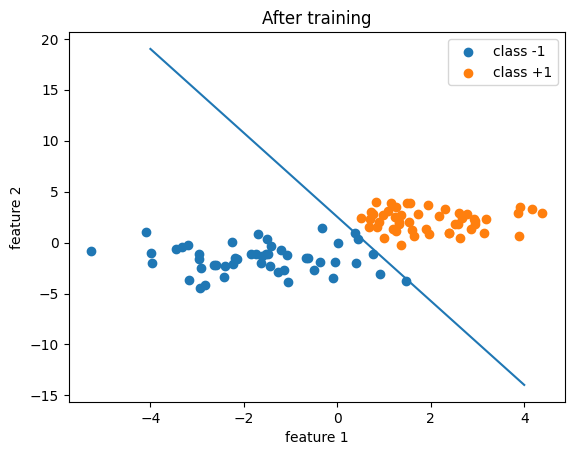

In [ ]:
x1_min = -4
x2_min = -(perceptron.w[0] + perceptron.w[1] * x1_min)/ perceptron.w[2]
x1_max = +4
x2_max = -(perceptron.w[0] + perceptron.w[1] * x1_max)/ perceptron.w[2]

plt.plot([x1_min, x1_max], [x2_min, x2_max])
plt.scatter(X[y==-1,1], X[y==-1,2], label='class -1')
plt.scatter(X[y==1,1], X[y==1,2], label='class +1')
plt.title('After training')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.legend()
plt.show()